# Human Kidney Cancer Interface Deconvolution

In [1]:
import sys

import numpy as np
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq
from PIL import Image

from pathlib import Path
# sys.path.append('../src')
# from utils import *

import warnings
warnings.filterwarnings('ignore')

from gctsvg.preprocessing import common, singlecell, st, kidneycancer


/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Preliminaries

0. Load Human Kidney Cancer Interface ST Data.
1. Save image as tif.

In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
output_dir = Path('ST checkpoints/Human Kidney Cancer')
patient_id = 'PD47171'

In [3]:
adata_st_inter = sc.read(data_dir / 'visium_merge_inter_upload.h5ad')
adata_st_inter

AnnData object with n_obs × n_vars = 27912 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499406', 'mean_counts-6800STDY12499406', 'log1p_mean_counts-6800STDY12499406', 'pct_dropout_by_counts-6800STDY12499406', 'total_counts-6800STDY12499406', 'log1p_total_counts-6800STDY12499406', 'n_cells_by_counts-6800STDY12499407', 'mean_counts-6800STDY12499407', 'log1p_mean_counts-6800STDY12499407', 'pct_dropout_by_counts-6800STDY12499407', 'total_counts-6800STDY12499407', 'log1p_total_counts-6800STDY12499407', 'n_cells_by_counts-6800STDY12499408', 'mean_counts-6800STDY12499408', 'log1p_mean_counts-6800STDY12499408', 'pct_dropout_by_counts-6800STDY12499408', 'tot

In [4]:
adata_st_inter = kidneycancer.extract_st_patient_data(adata_st_inter, patient_id)
adata_st_inter

AnnData object with n_obs × n_vars = 2048 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

In [5]:
# filter mitochondrial genes and genes/cells with low expression level
adata_st_inter = common.filter(adata_st_inter, is_mt_gene=lambda adata: adata.var['mt'] == True)
adata_st_inter.var[adata_st_inter.var['mt'] == True]

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499411,mean_counts-6800STDY12499411,log1p_mean_counts-6800STDY12499411,pct_dropout_by_counts-6800STDY12499411,total_counts-6800STDY12499411,log1p_total_counts-6800STDY12499411
ENSEMBL,,,,,,,,,,


In [6]:
adata_st_inter.uns["spatial"]

{'spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A': {'images': {'hires': array([[[0.9137255 , 0.8901961 , 0.8901961 ],
           [0.9137255 , 0.8901961 , 0.8901961 ],
           [0.9137255 , 0.8901961 , 0.8901961 ],
           ...,
           [0.9254902 , 0.8980392 , 0.8901961 ],
           [0.92156863, 0.8980392 , 0.8901961 ],
           [0.91764706, 0.89411765, 0.8862745 ]],
   
          [[0.9137255 , 0.8901961 , 0.8901961 ],
           [0.9137255 , 0.89411765, 0.89411765],
           [0.9137255 , 0.8901961 , 0.8980392 ],
           ...,
           [0.9254902 , 0.8980392 , 0.8901961 ],
           [0.9254902 , 0.8980392 , 0.8901961 ],
           [0.91764706, 0.8901961 , 0.8901961 ]],
   
          [[0.9137255 , 0.8901961 , 0.8901961 ],
           [0.9137255 , 0.8901961 , 0.89411765],
           [0.9098039 , 0.8862745 , 0.89411765],
           ...,
           [0.9254902 , 0.89411765, 0.89411765],
           [0.9254902 , 0.8980392 , 0.8901961 ],
           [0.9254902 , 0.894

In [7]:
adata_st_inter

View of AnnData object with n_obs × n_vars = 2048 × 15413
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

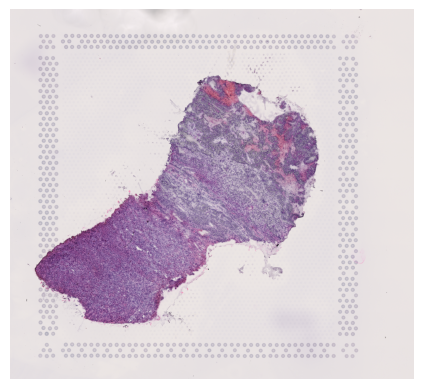

In [8]:
image = st.get_image_array(adata_st_inter)

# Plot without axes
plt.imshow(image)
plt.axis('off')  # Remove axis ticks and labels
plt.show()

In [9]:
image

array([[[233, 227, 227],
        [233, 227, 227],
        [233, 227, 227],
        ...,
        [236, 229, 227],
        [235, 229, 227],
        [234, 228, 226]],

       [[233, 227, 227],
        [233, 228, 228],
        [233, 227, 229],
        ...,
        [236, 229, 227],
        [236, 229, 227],
        [234, 227, 227]],

       [[233, 227, 227],
        [233, 227, 228],
        [232, 226, 228],
        ...,
        [236, 228, 228],
        [236, 229, 227],
        [236, 228, 228]],

       ...,

       [[228, 223, 227],
        [229, 223, 226],
        [230, 224, 226],
        ...,
        [233, 227, 226],
        [234, 227, 228],
        [234, 227, 228]],

       [[228, 223, 227],
        [229, 223, 226],
        [229, 224, 226],
        ...,
        [233, 227, 227],
        [233, 228, 227],
        [233, 228, 225]],

       [[228, 223, 227],
        [229, 223, 226],
        [229, 223, 226],
        ...,
        [234, 228, 228],
        [234, 228, 227],
        [232, 228, 225]]

In [10]:
if not Path.exists(output_dir):
    Path.mkdir(output_dir, parents=True)
adata_st_inter.write(output_dir / 'Human Kidney Cancer Interface.h5ad')
pil_image = Image.fromarray(image)
pil_image.save(output_dir / 'Human Kidney Cancer Interface.tif')

In [20]:
adata_st_inter.uns["spatial"]["spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A"]['scalefactors']

{'fiducial_diameter_fullres': 118.73269475478024,
 'spot_diameter_fullres': 73.50119199105443,
 'tissue_hires_scalef': 0.18601191,
 'tissue_lowres_scalef': 0.05580357}

In [24]:
6116 / 0.05580357

109598.72280572732

In [11]:
type(adata_st_inter.uns["spatial"]["spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A"]["images"]["hires"])

numpy.ndarray

In [12]:
# img_arr = adata_st_inter.uns["spatial"]["spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A"]["images"]["hires"]
# img_container = sq.im.ImageContainer(img_arr)
# img_container.save(output_dir / 'Human Kidney Cancer Interface.tif')

In [13]:
# img_container

In [14]:
# img_container.show()

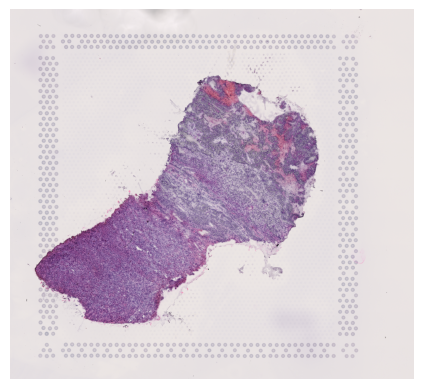

In [15]:
# Open the .tif image
saved_image = plt.imread(output_dir / 'Human Kidney Cancer Interface.tif')

# Display
plt.imshow(saved_image)
plt.axis('off')
plt.show()

In [18]:
saved_image.shape

(1834, 2000, 3)

## Step1: Nuclei segmentation

### Core
```
python ./SpatialScope/src/Nuclei_Segmentation.py --tissue "Human Kidney Cancer Interface" \
--out_dir ./spatialscope_output \
--ST_Data ./"ST checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer Interface.h5ad" \
--Img_Data ./"ST checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer Interface".tif
```

## Step1: Single-Doublet Classification
```
python ./SpatialScope/src/Singlet_Doublet_Classification.py --tissue "Human Kidney Cancer Interface" \
--out_dir ./spatialscope_output \
--ST_Data ./"ST checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer Interface.h5ad" \
--SC_Data ./"scRNA ref checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer".h5ad \
--cell_class_column broad_type
```

## Step2: Cell type identification

### Core
```
python ./SpatialScope/src/Cell_Type_Identification.py --tissue "Human Kidney Cancer Interface" \
--out_dir ./spatialscope_output \
--ST_Data ./spatialscope_output/"Human Kidney Cancer Interface"/sp_adata_ns.h5ad \
--SC_Data ./"scRNA ref checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer".h5ad \
--cell_class_column broad_type
```

## Step3: Gene expression decomposition

Limited by GPU memory, we can only handle at most about 1000 spots in 4 GPUs at a time, so we decompose 1024 spots at a time.

If you are only interested in the ROI region shown in the main text, you can perform gene expression decomposition on this ROI region only for the sake of time

```
python ./SpatialScope/src/Decomposition.py --tissue "Human Kidney Cancer Interface" \
--out_dir ./spatialscope_output \
--SC_Data ./"scRNA ref checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer".h5ad \
--cell_class_column broad_type \
--ckpt_path ./"scRNA ref checkpoints"/"Human Kidney Cancer"/model_10000.pt \
--spot_range 0,1024 \
--gpu 0,1,2,3

python ./SpatialScope/src/Decomposition.py --tissue "Human Kidney Cancer Interface" \
--out_dir ./spatialscope_output \
--SC_Data ./"scRNA ref checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer".h5ad \
--cell_class_column broad_type \
--ckpt_path ./"scRNA ref checkpoints"/"Human Kidney Cancer"/model_10000.pt \
--spot_range 0,2048 \
--gpu 0,1,2,3
```